In [2]:
import os

print("Current directory:", os.getcwd())

Current directory: /Users/zakariyakalakhy/Desktop/Master2/customer-churn-prediction


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("data/raw/telco_customer_churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

# Statistical summary
df.describe(include="all")

Dataset shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [6]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [7]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [8]:
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [9]:
# Check empty or whitespace-only values
print("Empty TotalCharges:",
      (df["TotalCharges"].str.strip() == "").sum())

# Check data types
print("\nTotalCharges type:")
print(df["TotalCharges"].dtype)

Empty TotalCharges: 11

TotalCharges type:
object


In [10]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [12]:
empty_charges = df["TotalCharges"].str.strip() == ""

print(df.loc[empty_charges, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


In [13]:
# Replace empty strings with missing values
df["TotalCharges"] = df["TotalCharges"].str.strip()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Customers with zero tenure have no accumulated charges
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify
print(df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

df[["tenure", "MonthlyCharges", "TotalCharges"]].head()

float64
Missing values: 0


,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


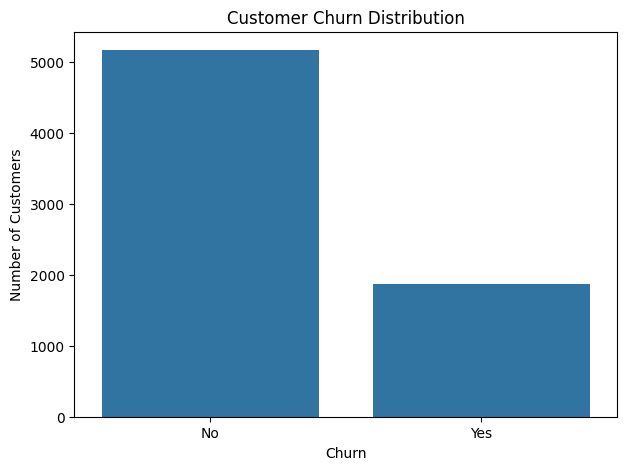

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


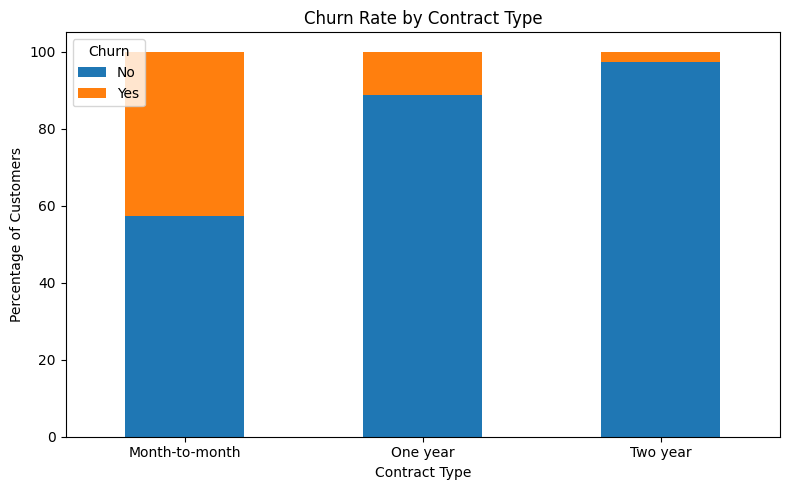

In [15]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract)

churn_by_contract.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [ ]:
### 3.2 Churn Rate by Contract Type

The analysis shows a strong relationship between contract type and customer churn.

- Month-to-month contracts have the highest churn rate (42.71%).
- One-year contracts have a churn rate of 11.27%.
- Two-year contracts have the lowest churn rate (2.83%).

This suggests that customers with longer-term contracts are more likely to remain with the company.
Contract type may therefore be an important feature for predicting customer churn.

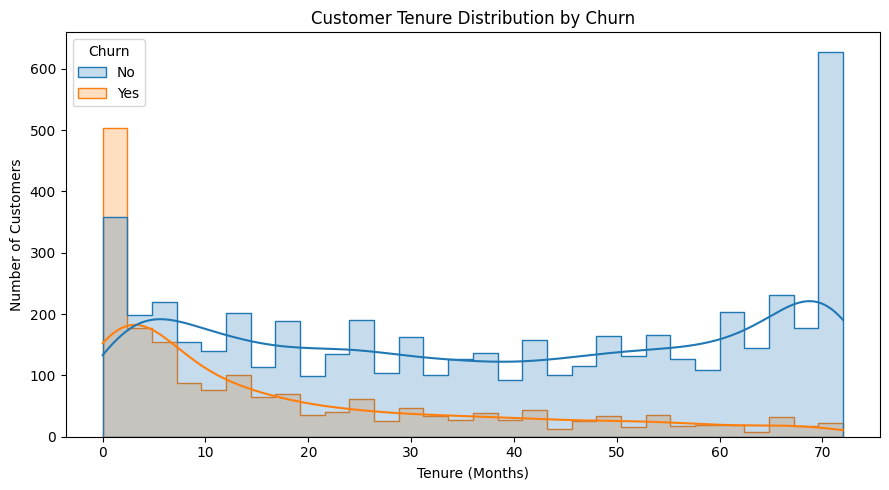

In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [17]:
print(df.groupby("Churn")["tenure"].describe())

        count       mean        std  min   25%   50%   75%   max
Churn                                                           
No     5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0


In [ ]:
### 3.3 Customer Tenure Analysis

The analysis reveals a significant difference in customer tenure:

- Customers who stayed have an average tenure of 37.57 months.
- Customers who churned have an average tenure of 17.98 months.
- The median tenure is 38 months for retained customers and only 10 months for churned customers.

This suggests that customers with shorter relationships with the company are more likely to churn. Tenure may be an important feature for our prediction models.

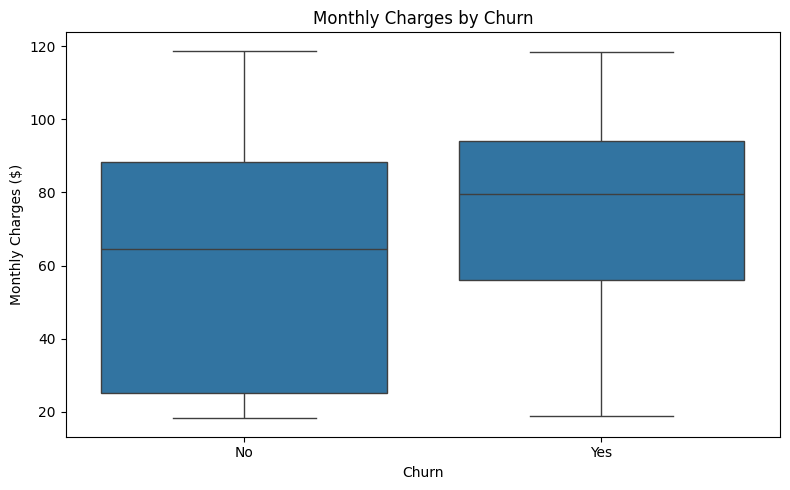

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()

In [19]:
print(df.groupby("Churn")["MonthlyCharges"].describe())

        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
No     5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
Yes    1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


In [ ]:
### 3.4 Monthly Charges Analysis

The analysis reveals a difference in monthly charges between customers who stayed and those who churned.

- Customers who stayed paid an average of $61.27 per month.
- Customers who churned paid an average of $74.44 per month.
- The median monthly charge was $64.43 for retained customers and $79.65 for churned customers.

This suggests that customers with higher monthly charges may have a greater tendency to churn. MonthlyCharges could therefore be a useful feature for our prediction models.

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


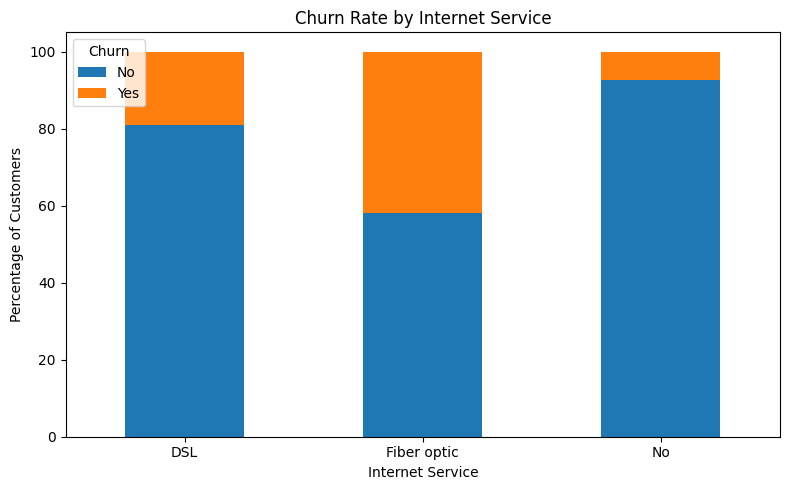

In [20]:
churn_by_internet = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_internet)

churn_by_internet.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [ ]:
### 3.5 Churn Analysis by Internet Service

The analysis reveals differences in churn rates across internet service types:

- Fiber optic customers have the highest churn rate (approximately 40%).
- DSL customers have a churn rate of approximately 20%.
- Customers without internet service have the lowest churn rate (approximately 5%).

Internet service type may be an important feature for predicting customer churn.

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


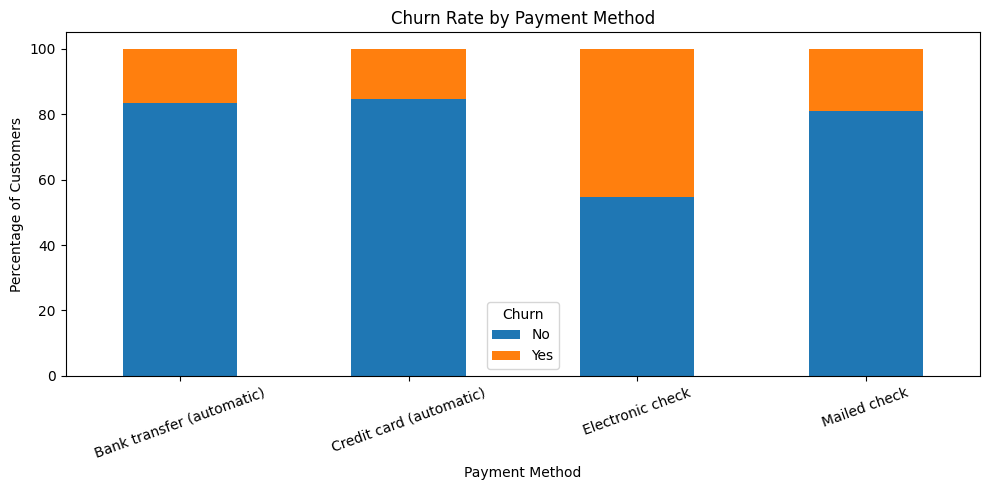

In [21]:
churn_by_payment = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_payment)

churn_by_payment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=20)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [ ]:
### 3.6 Churn Analysis by Payment Method

The analysis reveals differences in churn rates across payment methods:

- Electronic check has the highest churn rate (45.29%).
- Credit card (automatic) has the lowest churn rate (15.24%).
- Bank transfer (automatic) has a churn rate of 16.71%.
- Mailed check has a churn rate of 19.11%.

Customers using electronic checks appear more likely to churn. PaymentMethod may therefore be an important feature for our prediction models.

Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


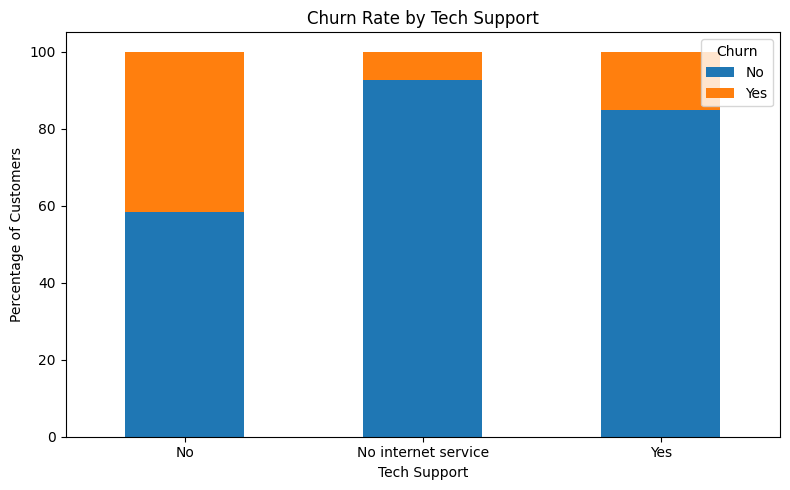

In [22]:
churn_by_support = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_support)

churn_by_support.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [ ]:
### 3.7 Churn Analysis by Tech Support

The analysis reveals differences in churn rates based on technical support availability:

- Customers without tech support have the highest churn rate (41.64%).
- Customers with tech support have a churn rate of 15.17%.
- Customers without internet service have the lowest churn rate (7.40%).

This suggests that technical support availability may be an important factor in customer retention and churn prediction.

In [23]:
numerical_df = df.select_dtypes(include=["int64", "float64"])

correlation = numerical_df.corr()

print(correlation)

                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016567        0.220173      0.103006
tenure               0.016567  1.000000        0.247900      0.826178
MonthlyCharges       0.220173  0.247900        1.000000      0.651174
TotalCharges         0.103006  0.826178        0.651174      1.000000


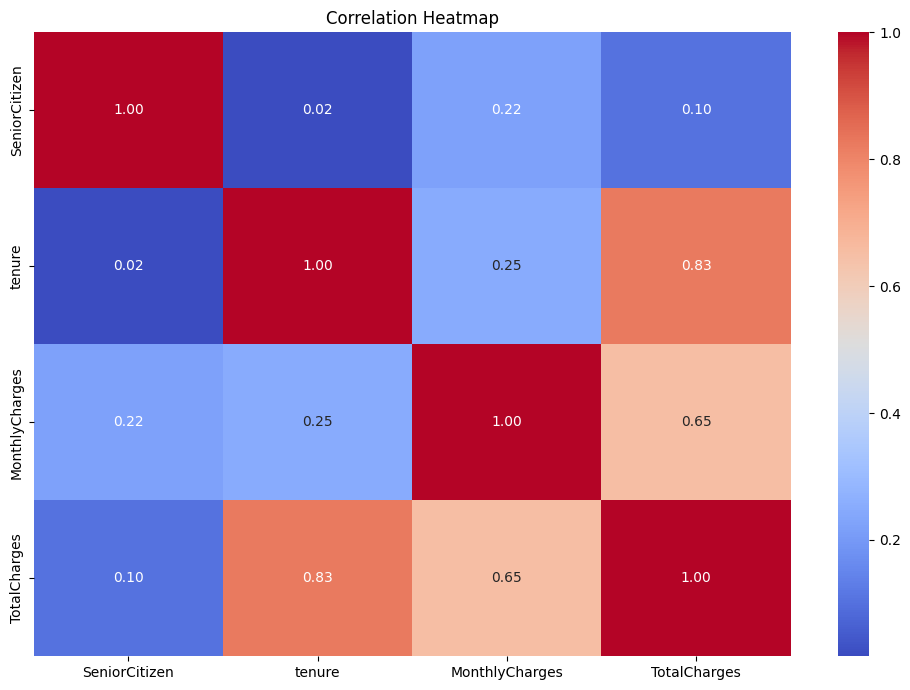

In [24]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [ ]:
### 3.8 Numerical Correlation Analysis

The correlation analysis reveals several relationships between numerical variables:

- Tenure and TotalCharges have a strong positive correlation (0.826).
- MonthlyCharges and TotalCharges have a positive correlation (0.651).
- Tenure and MonthlyCharges have a relatively weak positive correlation (0.248).
- SeniorCitizen has weak correlations with the other numerical variables.

The strongest relationship is between tenure and total charges, which is expected because customers who stay longer generally accumulate more charges.

These relationships will be considered during data preprocessing and model development.

In [ ]:
# 4. Data Preprocessing

In [25]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [26]:
df = df.drop(columns=["customerID"])

print("New dataset shape:", df.shape)
print(df.head())

New dataset shape: (7043, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1 

In [27]:
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [28]:
# Keep Churn separate from the input features
categorical_features = [
    col for col in categorical_columns if col != "Churn"
]

# Convert categorical features into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Convert target variable into binary values
df_encoded["Churn"] = df_encoded["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("New dataset shape:", df_encoded.shape)
print(df_encoded.head())

New dataset shape: (7043, 31)
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  Churn  gender_Male  \
0              0       1           29.85         29.85      0            0   
1              0      34           56.95       1889.50      0            1   
2              0       2           53.85        108.15      1            1   
3              0      45           42.30       1840.75      0            1   
4              0       2           70.70        151.65      1            0   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0            1               0                 0   
1            0               0                 1   
2            0               0                 1   
3            0               0                 0   
4            0               0                 1   

   MultipleLines_No phone service  ...  StreamingTV_No internet service  \
0                               1  ...                                0   
1                               0  ...

In [29]:
# Features: all columns except Churn
X = df_encoded.drop(columns=["Churn"])

# Target: Churn
y = df_encoded["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 30)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (5634, 30)
Testing features: (1409, 30)

Training target distribution:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.456352
1    26.543648
Name: proportion, dtype: float64


In [31]:
from sklearn.preprocessing import StandardScaler

# Numerical columns to scale
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform test data using the same scaler
X_test[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

print("Feature scaling completed!")

print("\nTraining data:")
print(X_train[numerical_features].head())

print("\nTesting data:")
print(X_test[numerical_features].head())

Feature scaling completed!

Training data:
        tenure  MonthlyCharges  TotalCharges
3738  0.102371       -0.521976     -0.262257
3151 -0.711743        0.337478     -0.503635
4860 -0.793155       -0.809013     -0.749883
3867 -0.263980        0.284384     -0.172722
3810 -1.281624       -0.676279     -0.989374

Testing data:
        tenure  MonthlyCharges  TotalCharges
437   1.608483        1.629976      2.706828
2280 -0.996684        1.168725     -0.610260
2235  0.346606        0.445324      0.400116
4460 -0.589626        0.440347     -0.364451
3761  1.608483        0.588013      1.588421


In [32]:
from sklearn.linear_model import LogisticRegression

# Create the model
log_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [33]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [34]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [35]:
# Logistic Regression predictions
y_pred_log = log_model.predict(X_test)

# Decision Tree predictions
y_pred_tree = tree_model.predict(X_test)

# Random Forest predictions
y_pred_rf = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 actual values:")
print(y_test.head(10).values)

print("\nLogistic Regression predictions:")
print(y_pred_log[:10])

print("\nDecision Tree predictions:")
print(y_pred_tree[:10])

print("\nRandom Forest predictions:")
print(y_pred_rf[:10])

Predictions generated successfully!

First 10 actual values:
[0 0 0 0 0 0 0 0 0 1]

Logistic Regression predictions:
[0 1 0 1 0 1 1 0 0 1]

Decision Tree predictions:
[0 1 0 1 0 1 1 0 0 0]

Random Forest predictions:
[0 1 0 0 0 1 1 0 0 1]


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf)
    ]
})

results = results.sort_values(
    by="F1-score",
    ascending=False
)

print(results.round(4))

                 Model  Accuracy  Precision  Recall  F1-score
1        Decision Tree    0.7346     0.5000  0.8075    0.6176
2        Random Forest    0.7615     0.5377  0.7246    0.6173
0  Logistic Regression    0.7381     0.5043  0.7834    0.6136


In [37]:
from sklearn.metrics import confusion_matrix

models_predictions = {
    "Logistic Regression": y_pred_log,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf
}

for model_name, predictions in models_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    print(f"\n{model_name}")
    print("Rows = Actual | Columns = Predicted")
    print(pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"]
    ))


Logistic Regression
Rows = Actual | Columns = Predicted
                 Predicted No Churn  Predicted Churn
Actual No Churn                 747              288
Actual Churn                     81              293

Decision Tree
Rows = Actual | Columns = Predicted
                 Predicted No Churn  Predicted Churn
Actual No Churn                 733              302
Actual Churn                     72              302

Random Forest
Rows = Actual | Columns = Predicted
                 Predicted No Churn  Predicted Churn
Actual No Churn                 802              233
Actual Churn                    103              271


In [38]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=["No Churn", "Churn"]
    )
)

Decision Tree Classification Report:

              precision    recall  f1-score   support

    No Churn       0.91      0.71      0.80      1035
       Churn       0.50      0.81      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.73      0.75      1409



In [39]:
import os
import joblib

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save the trained model
joblib.dump(tree_model, "models/decision_tree_model.pkl")

print("Decision Tree model saved successfully!")

Decision Tree model saved successfully!


In [40]:
joblib.dump(scaler, "models/scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [41]:
joblib.dump(X.columns.tolist(), "models/feature_names.pkl")

print("Feature names saved successfully!")

Feature names saved successfully!
